# Baseline-модель для PTB-XL

**Второй чекпоинт · DL-трек**

В этом ноутбуке я обучаю простую модель, которая по сигналу ЭКГ предсказывает пять диагностических категорий: `NORM`, `MI`, `STTC`, `CD` и `HYP`.

На этом этапе важно не получить максимально возможное качество, а построить **понятный baseline**, с которым затем можно сравнивать более сложные модели. Для этого использую логистическую регрессию и простые характеристики 12 отведений ЭКГ.

**Данные:** [PTB-XL, версия 1.0.3](https://physionet.org/content/ptb-xl/1.0.3/). Подготовка по логике `labels.py` и EDA (Ульяны)

## 1. Подготовка файлов

Нужны **три части датасета**:

- `ptbxl_database.csv` — метаданные ЭКГ, включая пути к сигналам и исходные SCP-коды;
- `scp_statements.csv` — справочник для перевода SCP-кодов в пять диагностических классов;
- папка `records100` — сами сигналы ЭКГ с частотой 100 Гц. Каждая запись состоит из пары `.hea` и `.dat`.

 `records500` нам сейчас пока не нужны.


In [ ]:
# Библиотека для чтения сигналов формата WFDB
!pip -q install wfdb

In [ ]:
import ast
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import wfdb
from IPython.display import display
from tqdm.auto import tqdm

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, precision_score, recall_score

### Распаковываем загруженный архив


In [7]:
!unzip -q -o /content/ptbxl.zip -d /content/

In [9]:
data_path = Path('/content/ptbxl')

database_path = data_path / 'ptbxl_database.csv'
statements_path = data_path / 'scp_statements.csv'

## 2. Загружаем метаданные и готовим метки

Тут повторяем логику EDA. В исходном `scp_codes` хранится словарь диагностических кодов. По справочнику `scp_statements.csv` мы определяем, к каким крупным категориям относится запись.

**Важный момент:** одна ЭКГ может иметь сразу несколько диагнозов. Поэтому это **multi-label классификация**: для каждого из пяти классов модель отдельно решает, есть он или нет.

In [10]:
df = pd.read_csv(database_path)
scp = pd.read_csv(statements_path, index_col=0)

print('Размер базы:', df.shape)
print('Размер справочника:', scp.shape)
df[['ecg_id', 'patient_id', 'strat_fold', 'filename_lr', 'scp_codes']].head()

Размер базы: (21799, 28)
Размер справочника: (71, 12)


,ecg_id,patient_id,strat_fold,filename_lr,scp_codes
0,1,15709.0,3,records100/00000/00001_lr,"{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}"
1,2,13243.0,2,records100/00000/00002_lr,"{'NORM': 80.0, 'SBRAD': 0.0}"
2,3,20372.0,5,records100/00000/00003_lr,"{'NORM': 100.0, 'SR': 0.0}"
3,4,17014.0,3,records100/00000/00004_lr,"{'NORM': 100.0, 'SR': 0.0}"
4,5,17448.0,4,records100/00000/00005_lr,"{'NORM': 100.0, 'SR': 0.0}"


In [11]:
CLASSES = ['NORM', 'MI', 'STTC', 'CD', 'HYP']

df['scp_dict'] = df['scp_codes'].apply(ast.literal_eval)
scp_final = scp[(scp['diagnostic'] == 1) & scp['diagnostic_class'].notna()]

def get_superclass(scp_codes):
    classes = set()
    for code in scp_codes:
        if code in scp_final.index:
            classes.add(scp_final.loc[code, 'diagnostic_class'])
    return sorted(classes)

df['scp_class'] = df['scp_dict'].apply(get_superclass)

for class_name in CLASSES:
    df[class_name] = df['scp_class'].apply(lambda classes: int(class_name in classes))

df[['ecg_id', 'scp_class'] + CLASSES].head()

,ecg_id,scp_class,NORM,MI,STTC,CD,HYP
0,1,[NORM],1,0,0,0,0
1,2,[NORM],1,0,0,0,0
2,3,[NORM],1,0,0,0,0
3,4,[NORM],1,0,0,0,0
4,5,[NORM],1,0,0,0,0


In [ ]:
print('Распределение классов:')
print(df[CLASSES].sum().sort_values(ascending=False))

print()
print('Количество диагностических меток на одну ЭКГ:')
print(df[CLASSES].sum(axis=1).value_counts().sort_index())

### Что делаем с записями без целевых меток?

Некоторые ЭКГ не получают ни одной метки из выбранных пяти классов. Это не обязательно «здоровые» записи: в исходной разметке могут быть, например, только ритмические или другие недиагностические коды.

Для первичного baseline я **исключаю записи без выбранных диагностических меток**, чтобы не считать их заведомо отрицательными примерами всех пяти диагнозов. Это решение применяю одинаково к обучению, валидации и тесту. В дальнейшем его можно проверить отдельно.

In [12]:
df_model = df[df[CLASSES].sum(axis=1) > 0].copy()

print('Всего записей:', len(df))
print('Оставили для baseline:', len(df_model))
print('Исключили:', len(df) - len(df_model))

Всего записей: 21799
Оставили для baseline: 21388
Исключили: 411


## 3. Разделяем данные на train, validation и test

В PTB-XL уже есть готовый столбец `strat_fold`. Как говорилось в EDA, авторы рекомендуют использовать **фолды 1–8 для обучения, 9 для валидации и 10 для тестирования**. Это важно ещё и потому, что все записи одного пациента находятся в одном фолде: так модель не увидит ЭКГ одного и того же человека одновременно при обучении и тестировании.


In [14]:
train_df = df_model[df_model['strat_fold'] <= 8].copy()
val_df = df_model[df_model['strat_fold'] == 9].copy()
test_df = df_model[df_model['strat_fold'] == 10].copy()

print('Train:', len(train_df))
print('Validation:', len(val_df))
print('Test:', len(test_df))

Train: 17084
Validation: 2146
Test: 2158


## 4. Считываем ЭКГ и получаем признаки

До этого у нас были только **метки** диагнозов. Теперь начинаем работать с самим сигналом.

В `records100` каждая запись — это 10 секунд ЭКГ, 12 отведений и частота 100 Гц. То есть, обычно мы получаем массив размером **1000 × 12**. Библиотека `wfdb` умеет прочитать его по пути из столбца `filename_lr`.

Вот так это выглядит для одной записи

In [15]:
first_record = data_path / df_model['filename_lr'].iloc[0]
signal, info = wfdb.rdsamp(str(first_record))

print('Размер сигнала:', signal.shape)
print('Частота:', info['fs'], 'Гц')
print('Отведения:', info['sig_name'])
print('Единицы измерения:', info['units'])

Размер сигнала: (1000, 12)
Частота: 100 Гц
Отведения: ['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
Единицы измерения: ['mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV', 'mV']


### Какие признаки берем

Чтобы не обучать пока сложную модель на всех 12 000 значениях сигнала, для **каждого отведения** рассчитаем четыре простые характеристики:

- `mean` — среднее значение сигнала;
- `std` — стандартное отклонение, то есть насколько сильно меняется амплитуда;
- `range` — разница между максимальным и минимальным значением;
- `diff` — средняя абсолютная разница между соседними точками; грубая характеристика того, как быстро изменяется сигнал.

Итого **12 × 4 = 48 признаков** на одну ЭКГ. Это заведомо упрощённое описание: форма комплексов QRS и зубцов P/T, а также временные интервалы здесь напрямую не учитываются. Но для первого интерпретируемого baseline этого достаточно.

**Не используем возраст, пол и остальные метаданные** тк наша основная задача сейчас распознавать диагностические классы **по ЭКГ**, поэтому на первом этапе берём признаки только из сигналов. Метки `scp_codes` и готовые диагнозы во вход модели не попадают.

### Рассчитываем характеристики для всех записей

Проходим по файлам `records100`, считываем сигнал и считаем статистики для 12 отведений.


In [16]:
features_path = Path('/content/ecg_features.csv')

if features_path.exists():
    features_df = pd.read_csv(features_path)
else:
    feature_rows = []

    for row in tqdm(df_model.itertuples(), total=len(df_model)):
        signal, info = wfdb.rdsamp(str(data_path / row.filename_lr))
        features = {'ecg_id': row.ecg_id}

        for i, lead in enumerate(info['sig_name']):
            values = signal[:, i]
            features[f'{lead}_mean'] = np.mean(values)
            features[f'{lead}_std'] = np.std(values)
            features[f'{lead}_range'] = np.ptp(values)
            features[f'{lead}_diff'] = np.mean(np.abs(np.diff(values)))

        feature_rows.append(features)

    features_df = pd.DataFrame(feature_rows)
    features_df.to_csv(features_path, index=False)

print('Размер таблицы признаков:', features_df.shape)
features_df.head()

  0%|          | 0/21388 [00:00<?, ?it/s]

Размер таблицы признаков: (21388, 49)


,ecg_id,I_mean,I_std,I_range,I_diff,II_mean,II_std,II_range,II_diff,III_mean,...,V4_range,V4_diff,V5_mean,V5_std,V5_range,V5_diff,V6_mean,V6_std,V6_range,V6_diff
0,1,0.001508,0.109022,0.901,0.033637,0.000723,0.083223,0.575,0.025407,-0.000778,...,0.914,0.026614,-0.000557,0.089204,0.627,0.021435,0.000832,0.101939,0.757,0.018738
1,2,-0.002181,0.133428,1.013,0.027497,-0.000165,0.249745,1.948,0.037291,0.002037,...,3.253,0.060535,0.006375,0.228674,2.331,0.045091,0.003389,0.186626,1.598,0.033853
2,3,-0.002770,0.121200,0.991,0.035177,0.005145,0.144389,1.003,0.028187,0.007927,...,1.445,0.034444,0.005362,0.110647,1.026,0.025862,0.004239,0.100842,0.833,0.020466
3,4,-0.003264,0.137803,1.079,0.040861,0.003502,0.438161,3.036,0.070125,0.006750,...,5.189,0.142956,-0.007380,0.394695,3.490,0.098566,-0.004061,0.297912,2.435,0.069600
4,5,-0.003769,0.082706,0.707,0.025714,-0.003054,0.236781,1.912,0.045273,0.000704,...,2.026,0.051336,0.000208,0.210904,1.680,0.043241,-0.000053,0.180209,1.418,0.037127


### Проверим получившуюся таблицу

Теперь **одна строка — одна ЭКГ**, а столбцы — это её характеристики. Проверяем, нет ли пропусков, и соединяем таблицу с метками по `ecg_id`.

In [17]:
print('Пропусков в таблице признаков:', features_df.isna().sum().sum())
print('Полных дублей по ecg_id:', features_df['ecg_id'].duplicated().sum())

data = df_model.merge(features_df, on='ecg_id', how='inner', validate='one_to_one')

feature_cols = features_df.columns.drop('ecg_id').tolist()
print('Число признаков:', len(feature_cols))

Пропусков в таблице признаков: 0
Полных дублей по ecg_id: 0
Число признаков: 48


## 5. Обучаем логистическую регрессию ()

Так как у нас многометочная классификация, то для каждого из пяти классов будем обучать отдельную бинарную модель — такой подход называется **One-vs-Rest**. Он подходит для нашей задачи, поскольку одна ЭКГ может одновременно иметь несколько меток.

Перед обучением:

- заменяем пропущенные числовые значения медианой, рассчитанной **только на train**;
- стандартизируем признаки, чтобы их масштаб не влиял на величину коэффициентов;
- учитываем дисбаланс с помощью `class_weight='balanced'`.

Эти преобразования объединены с моделью в `Pipeline`, поэтому данные из validation и test не влияют на параметры предобработки.

In [18]:
train = data[data['strat_fold'] <= 8]
val = data[data['strat_fold'] == 9]
test = data[data['strat_fold'] == 10]

X_train, y_train = train[feature_cols], train[CLASSES]
X_val, y_val = val[feature_cols], val[CLASSES]
X_test, y_test = test[feature_cols], test[CLASSES]

print('X_train:', X_train.shape, '| y_train:', y_train.shape)
print('X_val:', X_val.shape, '| y_val:', y_val.shape)
print('X_test:', X_test.shape, '| y_test:', y_test.shape)

X_train: (17084, 48) | y_train: (17084, 5)
X_val: (2146, 48) | y_val: (2146, 5)
X_test: (2158, 48) | y_test: (2158, 5)


In [20]:
model = OneVsRestClassifier(
    Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('lr', LogisticRegression(max_iter=2000, class_weight='balanced', random_state=42))
    ])
)

model.fit(X_train, y_train)

OneVsRestClassifier(estimator=Pipeline(steps=[('imputer',
                                               SimpleImputer(strategy='median')),
                                              ('scaler', StandardScaler()),
                                              ('lr',
                                               LogisticRegression(class_weight='balanced',
                                                                  max_iter=2000,
                                                                  random_state=42))]))

## 6. Смотрим качество модели

Сначала получаем вероятности каждого класса, затем для простоты считаем метку положительной при вероятности от `0.5`. Порог пока **не подбираем** (для простоты baseline).

Оцениваем F1 и:

- **ROC-AUC** — насколько хорошо модель разделяет положительные и отрицательные примеры независимо от порога;
- **Average Precision (AP)** — качество ранжирования положительных примеров; особенно полезно для редких классов;
- **Precision** — какая доля положительных предсказаний действительно правильная;
- **Recall** — какую долю реальных положительных записей модель нашла.

В таблице также будет доля класса (`prevalence`). Для AP это полезный ориентир: у случайного ранжирования AP примерно равен частоте класса. Accuracy здесь менее информативна из-за дисбаланса.

In [21]:
val_proba = model.predict_proba(X_val)
test_proba = model.predict_proba(X_test)

print('Вероятности для первых трёх ЭКГ:')
display(pd.DataFrame(test_proba[:3], columns=CLASSES).round(3))

Вероятности для первых трёх ЭКГ:


,NORM,MI,STTC,CD,HYP
0,0.563,0.451,0.522,0.228,0.171
1,0.570,0.460,0.336,0.427,0.094
2,0.288,0.674,0.436,0.410,0.472


In [22]:
def calculate_metrics(y_true, probabilities):
    predictions = (probabilities >= 0.5).astype(int)
    results = []

    for i, class_name in enumerate(CLASSES):
        true_labels = y_true[class_name]
        pred_labels = predictions[:, i]

        results.append({
            'class': class_name,
            'prevalence': true_labels.mean(),
            'ROC-AUC': roc_auc_score(true_labels, probabilities[:, i]),
            'AP': average_precision_score(true_labels, probabilities[:, i]),
            'precision': precision_score(true_labels, pred_labels, zero_division=0),
            'recall': recall_score(true_labels, pred_labels, zero_division=0),
            'F1': f1_score(true_labels, pred_labels, zero_division=0)
        })

    return pd.DataFrame(results).set_index('class')

In [23]:
val_metrics = calculate_metrics(y_val, val_proba)
test_metrics = calculate_metrics(y_test, test_proba)

print('VALIDATION')
display(val_metrics.round(3))

print('TEST')
display(test_metrics.round(3))

VALIDATION


,prevalence,ROC-AUC,AP,precision,recall,F1
class,,,,,,
NORM,0.445,0.800,0.710,0.649,0.812,0.721
MI,0.252,0.756,0.477,0.446,0.719,0.551
STTC,0.246,0.724,0.450,0.420,0.593,0.491
CD,0.231,0.790,0.587,0.490,0.665,0.564
HYP,0.125,0.857,0.473,0.380,0.743,0.503


TEST


,prevalence,ROC-AUC,AP,precision,recall,F1
class,,,,,,
NORM,0.446,0.788,0.691,0.646,0.789,0.710
MI,0.255,0.743,0.494,0.421,0.671,0.518
STTC,0.241,0.708,0.442,0.405,0.591,0.481
CD,0.230,0.757,0.561,0.450,0.611,0.518
HYP,0.121,0.838,0.459,0.345,0.706,0.463


In [24]:
print('Средние значения на test:')
print('ROC-AUC (macro):', round(test_metrics['ROC-AUC'].mean(), 3))
print('AP (macro):', round(test_metrics['AP'].mean(), 3))
print('F1 (macro):', round(test_metrics['F1'].mean(), 3))

Средние значения на test:
ROC-AUC (macro): 0.767
AP (macro): 0.53
F1 (macro): 0.538


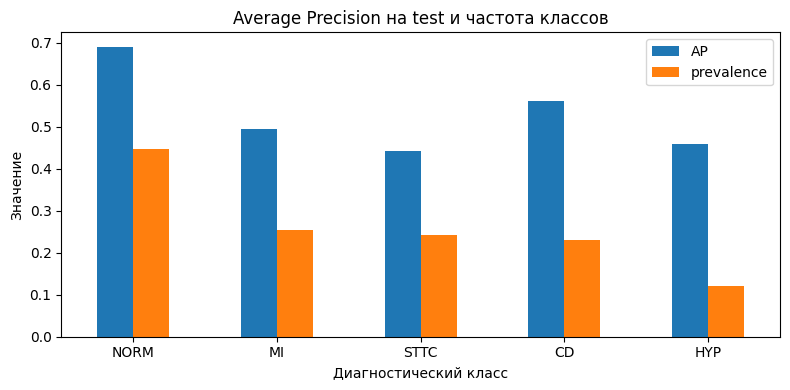

In [25]:
# Сравним качество AP с частотой каждого класса в тестовой выборке
ax = test_metrics[['AP', 'prevalence']].plot(kind='bar', figsize=(8, 4))
ax.set_title('Average Precision на test и частота классов')
ax.set_ylabel('Значение')
ax.set_xlabel('Диагностический класс')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

### Наблюдения по качеству


На тестовой выборке модель показала **ROC-AUC macro = 0.767, AP macro = 0.530 и F1 macro = 0.538**. Для первого baseline, построенного всего на 48 статистических признаках ЭКГ, модель уже способна различать диагностические категории, хотя качество заметно отличается в зависимости от класса.

Лучше всего по F1 модель распознаёт **NORM** (0.710). Для этого класса также получено самое высокое значение AP (0.691). При этом максимальный ROC-AUC оказался у **HYP** (0.838), несмотря на то что этот класс встречается реже остальных — примерно в 12% тестовых записей.

Интересно, что высокий ROC-AUC для HYP не означает столь же хорошего качества бинарных предсказаний. У этого класса самый низкий F1 (0.463): модель находит около 71% положительных примеров (Recall = 0.706), но Precision составляет всего 0.345. То есть достаточно часто она ошибочно относит записи к HYP. Вероятно, здесь сказывается и дисбаланс классов, и использование единого порога 0.5 без дополнительной настройки.

Наиболее сложным классом с точки зрения разделения положительных и отрицательных записей оказался **STTC**: ROC-AUC = 0.708, AP = 0.442. Возможно, для распознавания изменений ST-T недостаточно общих статистик амплитуды сигнала, поскольку они не сохраняют информацию о форме отдельных участков ЭКГ.

По сравнению с валидационной выборкой качество на тестовой немного снизилось практически по всем метрикам и классам. Например, ROC-AUC для MI изменился с 0.756 до 0.743, а для HYP — с 0.857 до 0.838. При этом резкого падения качества нет, поэтому результаты выглядят достаточно устойчивыми на отложенной выборке.

В целом baseline показывает, что даже простые характеристики ЭКГ содержат полезную информацию для классификации. Однако для некоторых диагнозов текущего представления сигнала явно недостаточно.

## 7. Интерпретация признаков


In [26]:
coef_df = pd.DataFrame({
    class_name: model.estimators_[i].named_steps['lr'].coef_[0]
    for i, class_name in enumerate(CLASSES)
}, index=feature_cols)

for class_name in CLASSES:
    important = coef_df[class_name].abs().nlargest(5).index
    print()
    print(f'{class_name}: пять признаков с наибольшими |коэффициентами|')
    print(coef_df.loc[important, class_name].round(3))


NORM: пять признаков с наибольшими |коэффициентами|
AVR_diff    2.035
AVR_std     1.527
V1_diff    -1.450
AVL_diff   -1.187
V1_range    1.079
Name: NORM, dtype: float64

MI: пять признаков с наибольшими |коэффициентами|
AVL_std     1.289
AVL_diff    1.227
I_std      -1.122
AVF_std    -0.888
I_diff     -0.771
Name: MI, dtype: float64

STTC: пять признаков с наибольшими |коэффициентами|
V1_mean    -0.960
V1_diff     0.686
AVL_diff    0.622
V1_range   -0.619
V3_range    0.592
Name: STTC, dtype: float64

CD: пять признаков с наибольшими |коэффициентами|
AVR_std    -2.408
I_std       1.929
II_std      1.654
AVL_diff    0.893
V1_range   -0.842
Name: CD, dtype: float64

HYP: пять признаков с наибольшими |коэффициентами|
AVF_diff    1.321
AVL_diff    1.222
I_diff     -1.214
V6_mean     1.079
V5_mean    -1.073
Name: HYP, dtype: float64


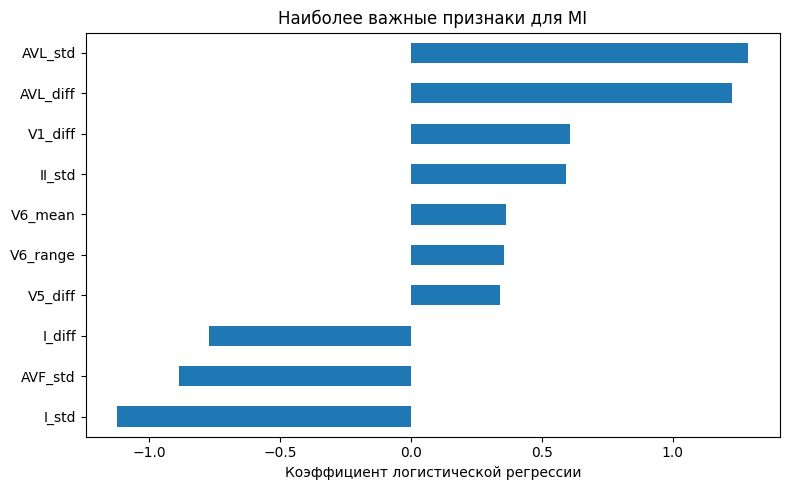

In [27]:
class_name = 'MI'
important = coef_df[class_name].abs().nlargest(10).index

ax = coef_df.loc[important, class_name].sort_values().plot.barh(figsize=(8, 5))
ax.set_title(f'Наиболее важные признаки для {class_name}')
ax.set_xlabel('Коэффициент логистической регрессии')
plt.tight_layout()
plt.show()

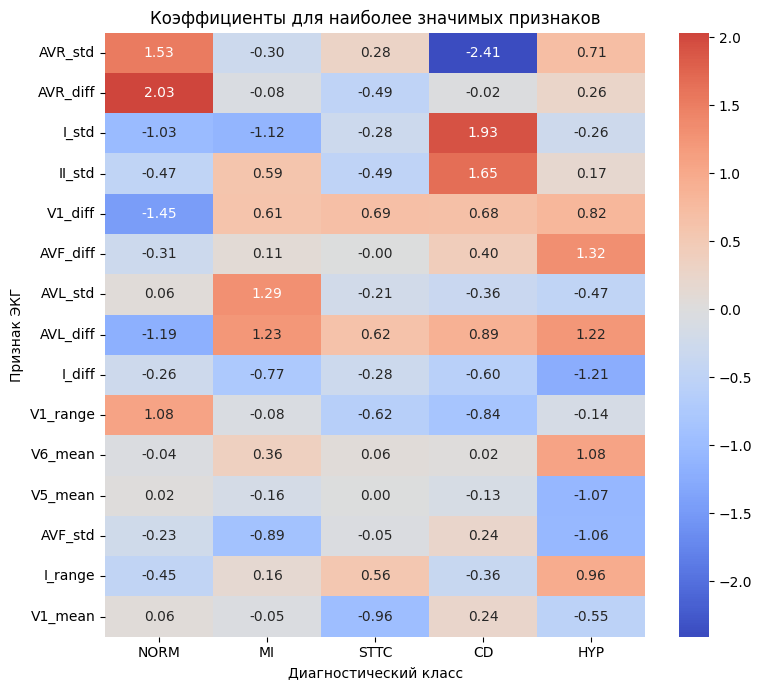

In [28]:
# Сравниваем важные характеристики сразу для всех пяти классов
important = coef_df.abs().max(axis=1).nlargest(15).index

plt.figure(figsize=(8, 7))
sns.heatmap(coef_df.loc[important], cmap='coolwarm', center=0, annot=True, fmt='.2f')
plt.title('Коэффициенты для наиболее значимых признаков')
plt.xlabel('Диагностический класс')
plt.ylabel('Признак ЭКГ')
plt.tight_layout()
plt.show()

### Наблюдения по признакам (заполнить после запуска)

По коэффициентам логистической регрессии видно, что модель использует разные характеристики ЭКГ для предсказания разных классов.

Например, для **MI** наиболее заметными оказались `AVL_std` (1.289), `AVL_diff` (1.227) и `I_std` (-1.122). Получается, что при предсказании этого класса модель особенно учитывает вариативность амплитуды и изменения сигнала между соседними точками в отведениях aVL и I.

Для **CD** выделяются `AVR_std` (-2.408), `I_std` (1.929) и `II_std` (1.654). Здесь существенную роль играет стандартное отклонение сигнала, причём коэффициенты имеют разные знаки в зависимости от отведения.

Для **STTC** наиболее выраженный коэффициент имеет `V1_mean` (-0.960), а для **HYP** — `AVF_diff` (1.321), `AVL_diff` (1.222) и `I_diff` (-1.214). Таким образом, разные диагностические категории связаны с разными сочетаниями характеристик сигнала.

Интересно, что среди наиболее значимых признаков часто встречаются `std` и `diff`, то есть характеристики изменчивости сигнала. Это говорит о том, что даже без анализа отдельных зубцов и интервалов ЭКГ модель может находить определённые закономерности.

Но стоит учитывать, что отведения ЭКГ взаимосвязаны, поэтому большие положительные и отрицательные коэффициенты могут частично объясняться корреляциями между признаками. Кроме того, мы используем достаточно грубое описание сигнала, которое не позволяет определить, какие конкретно участки ЭКГ повлияли на предсказание.

Тем не менее такой анализ полезен для baseline: он показывает, что модель действительно использует информацию из разных отведений, а не просто предсказывает наиболее распространённые классы.

## 8. Итоговые выводы

В рамках второго чекпоинта мы обучили простую baseline-модель для многометочной классификации ЭКГ на датасете PTB-XL.

Для обучения использовали записи `records100` с частотой дискретизации 100 Гц. Из каждого из 12 отведений извлекли четыре статистических признака: среднее значение, стандартное отклонение, размах и среднее абсолютное изменение между соседними точками. В результате каждая ЭКГ была представлена 48 числовыми признаками.

После исключения 411 записей без целевых диагностических меток осталось **21 388 ЭКГ**. Данные разделили на обучающую, валидационную и тестовую выборки по предложенным авторами PTB-XL фолдам, чтобы избежать пересечения пациентов между выборками.

В качестве baseline выбрали логистическую регрессию в схеме One-vs-Rest. На тестовой выборке получили следующие результаты:

- **ROC-AUC macro: 0.767**
- **Average Precision macro: 0.530**
- **F1 macro: 0.538**

Наиболее высокое качество по F1 модель показала для NORM (0.710), а по ROC-AUC — для HYP (0.838). При этом именно у HYP оказался самый низкий F1 (0.463), что показывает, насколько важно оценивать качество сразу по нескольким метрикам, особенно при дисбалансе классов.

Анализ коэффициентов показал, что модель использует разные характеристики сигнала для разных диагнозов. Чаще всего среди наиболее значимых признаков встречались стандартное отклонение и среднее абсолютное изменение сигнала, однако их нельзя напрямую интерпретировать как клинические признаки заболеваний.

**Главное ограничение текущего подхода** заключается в том, что мы сводим каждую 10-секундную запись ЭКГ к небольшому набору статистик. При этом теряется информация о последовательности сигнала, форме отдельных зубцов, комплексах QRS и временных интервалах, которая может быть важна для диагностики.

В дальнейшем планируем перейти к моделям глубокого обучения, например 1D-CNN, которые смогут работать непосредственно с временными рядами ЭКГ. Это позволит проверить, насколько использование полной формы сигнала улучшит классификацию по сравнению с простыми статистическими признаками.

Полученные метрики будем использовать как отправную точку для сравнения следующих моделей. При этом важно сохранить одинаковое разделение данных, набор диагностических классов и правила оценки, чтобы сравнение было корректным.